<a href="https://colab.research.google.com/github/AnkaRezaa/machine_learning_254107023002/blob/main/JS14/praktikum_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 1: Klasifikasi Cat vs. Dog Menggunakan Convolutional Neural Network (CNN)

### Deskripsi
Pada praktikum ini kita akan membuat model klasifikasi CNN sederhana pada kasus citra kucing (*cat*) dan anjing (*dog*).

### Dataset
Dataset merupakan data citra anjing dan kucing yang telah dibagi menjadi data *training* dan data *testing*:
- **Training set**: 8.000 citra (4.000 kucing, 4.000 anjing)
- **Test set**: 2.000 citra (1.000 kucing, 1.000 anjing)
- **Single prediction**: Citra untuk pengujian prediksi individu (`cat_or_dog_1.jpg` dan `cat_or_dog_2.jpg`)

### Langkah 1 - Import Library
Mengimpor TensorFlow dan `ImageDataGenerator` untuk augmentasi serta pra-pengolahan citra.

In [1]:
import tensorflow as tf
try:
    from tensorflow.keras.preprocessing.image import ImageDataGenerator
except ImportError:
    from keras.preprocessing.image import ImageDataGenerator
import os
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


### Langkah 2 - Pra Pengolahan Data
Pada tahap ini kita akan melakukan manipulasi pada citra yang digunakan. Manipulasi yang dilakukan diantaranya adalah normalisasi nilai piksel ($1/255$), koreksi kemiringan (*shear*), pembesaran (*zoom*), dan pembalikan horizontal (*horizontal flip*).

#### Langkah 2.1 - Pra Pengolahan Data Training

In [2]:
# Tentukan path folder dataset secara fleksibel
dataset_path = 'dataset'
for candidate in ['dataset', 'machine_learning_254107023002/JS14/dataset', 'JS14/dataset']:
    if os.path.exists(os.path.join(candidate, 'training_set')):
        dataset_path = candidate
        break

train_datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

training_set = train_datagen.flow_from_directory(
    os.path.join(dataset_path, 'training_set'),
    target_size=(64, 64),
    batch_size=32,
    class_mode='binary'
)

Found 8000 images belonging to 2 classes.


#### Langkah 2.2 - Pra Pengolahan Data Testing
Untuk data testing, kita hanya melakukan normalisasi nilai piksel ($1/255$) tanpa augmentasi data tambahan.

In [3]:
test_datagen = ImageDataGenerator(rescale=1./255)

test_set = test_datagen.flow_from_directory(
    os.path.join(dataset_path, 'test_set'),
    target_size=(64, 64),
    batch_size=32,
    class_mode='binary'
)

Found 2000 images belonging to 2 classes.


### Langkah 3 - Pembuatan Model CNN
Membangun arsitektur CNN dengan 2 layer konvolusi dan pooling, flattening, serta fully connected layer (Dense).

#### Langkah 3.1 - Inisiasi Model CNN

In [4]:
cnn = tf.keras.models.Sequential()

#### Langkah 3.2 - Pembuatan Layer Konvolusi 1
Menambahkan layer konvolusi 2D dengan 32 filter berukuran $3 \times 3$, fungsi aktivasi ReLU, dan input shape $[64, 64, 3]$ (citra RGB ukuran $64 \times 64$).

In [5]:
cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu', input_shape=[64, 64, 3]))

c:\laragon\www\Machine_learning\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


#### Langkah 3.3 - Pembuatan Layer Pooling 1
Menerapkan Max Pooling dengan ukuran pool $2 \times 2$ dan stride 2 untuk mereduksi dimensi spasial fitur.

In [6]:
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

#### Langkah 3.4 - Pembuatan Layer Konvolusi 2 dan Pooling 2
Menambahkan layer konvolusi kedua (32 filter berukuran $3 \times 3$, aktivasi ReLU) dan dilanjutkan dengan layer max pooling kedua.

In [7]:
cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

#### Langkah 3.5 - Flattening
Mengubah representasi matriks 2D fitur menjadi vektor 1D agar dapat diteruskan ke Fully Connected Layer.

In [8]:
cnn.add(tf.keras.layers.Flatten())

#### Langkah 3.6 - Fully Connected Layer 1 (Hidden Layer)
Menambahkan Dense layer dengan 128 unit neuron dan fungsi aktivasi ReLU.

In [9]:
cnn.add(tf.keras.layers.Dense(units=128, activation='relu'))

#### Langkah 3.7 - Fully Connected Layer 2 (Output Layer)
Menambahkan Dense output layer dengan 1 unit neuron dan aktivasi Sigmoid untuk menghasilkan probabilitas klasifikasi biner.

In [10]:
cnn.add(tf.keras.layers.Dense(units=1, activation='sigmoid'))

#### Langkah 3.8 - Compile Model CNN
Penggunaan loss function `binary_crossentropy` dikarenakan kita hanya melakukan klasifikasi pada dua kelas, yaitu kucing dan anjing.

In [11]:
cnn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 813,217 (3.10 MB)

 Trainable params: 813,217 (3.10 MB)

 Non-trainable params: 0 (0.00 B)

### Langkah 4 - Fit CNN
Melatih model CNN menggunakan data training dan mengevaluasinya pada data testing selama 25 epoch.

In [12]:
history = cnn.fit(x=training_set, validation_data=test_set, epochs=25)

Epoch 1/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 142s 565ms/step - accuracy: 0.5901 - loss: 0.6628 - val_accuracy: 0.5395 - val_loss: 0.7498
Epoch 2/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 20s 79ms/step - accuracy: 0.6845 - loss: 0.5972 - val_accuracy: 0.7125 - val_loss: 0.5615
Epoch 3/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 16s 66ms/step - accuracy: 0.7121 - loss: 0.5597 - val_accuracy: 0.7275 - val_loss: 0.5557
Epoch 4/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 16s 65ms/step - accuracy: 0.7410 - loss: 0.5226 - val_accuracy: 0.7595 - val_loss: 0.4993
Epoch 5/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 16s 66ms/step - accuracy: 0.7671 - loss: 0.4928 - val_accuracy: 0.7390 - val_loss: 0.5406
Epoch 6/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 16s 65ms/step - accuracy: 0.7699 - loss: 0.4846 - val_accuracy: 0.7815 - val_loss: 0.4725
Epoch 7/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 16s 66ms/step - accuracy: 0.7755 - loss: 0.4741 - val_accuracy: 0.7670 - val_loss: 0.5038
Epoch 8/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 16s 65ms/step - accuracy: 0.7874 - loss: 0.4475 

#### Visualisasi Hasil Pelatihan CNN
Plot grafik akurasi dan loss pada data training vs validation per epoch.

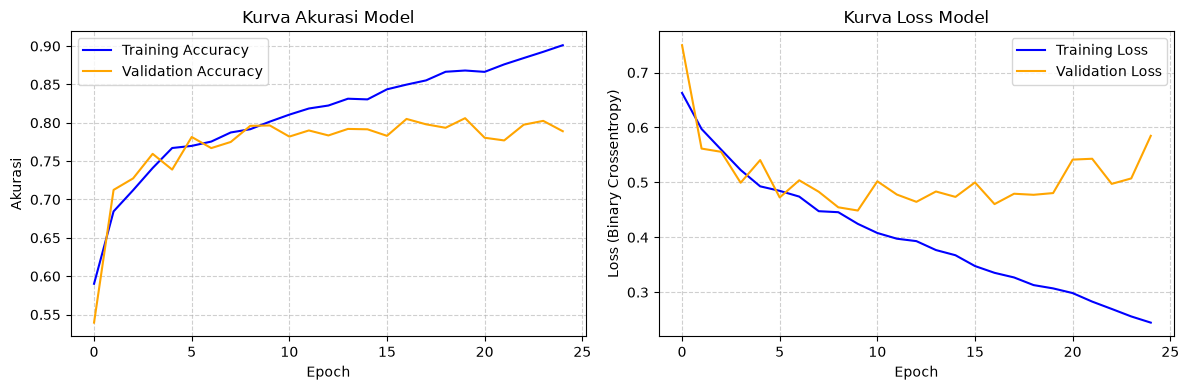

In [13]:
plt.figure(figsize=(12, 4))

# Grafik Akurasi
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy', color='blue')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange')
plt.title('Kurva Akurasi Model')
plt.xlabel('Epoch')
plt.ylabel('Akurasi')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Grafik Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss', color='blue')
plt.plot(history.history['val_loss'], label='Validation Loss', color='orange')
plt.title('Kurva Loss Model')
plt.xlabel('Epoch')
plt.ylabel('Loss (Binary Crossentropy)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Langkah 5 - Prediksi dengan 1 Citra
Pada langkah ini, kita akan mencoba melakukan prediksi pada 1 citra anjing dan kucing (`cat_or_dog_1.jpg` dan `cat_or_dog_2.jpg`).

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
Class Indices: {'cats': 0, 'dogs': 1}
Nilai Prediksi Probabilitas : 1.0000
Hasil Prediksi untuk cat_or_dog_1.jpg: DOG


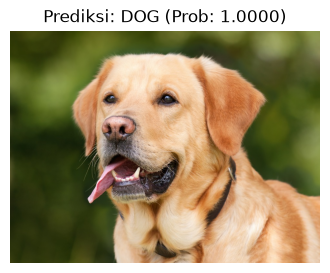

In [14]:
try:
    from tensorflow.keras.preprocessing import image
except ImportError:
    from keras.preprocessing import image

# 1. Prediksi citra pertama (cat_or_dog_1.jpg)
img_path_1 = os.path.join(dataset_path, 'single_prediction', 'cat_or_dog_1.jpg')
test_image_1 = image.load_img(img_path_1, target_size=(64, 64))
test_image_1 = image.img_to_array(test_image_1)
test_image_1 = np.expand_dims(test_image_1, axis=0)
test_image_1 = test_image_1 / 255.0  # Normalisasi nilai piksel

result_1 = cnn.predict(test_image_1)
print("Class Indices:", training_set.class_indices)
print(f"Nilai Prediksi Probabilitas : {result_1[0][0]:.4f}")

if result_1[0][0] >= 0.5:
    prediction_1 = 'dog'
else:
    prediction_1 = 'cat'

print(f"Hasil Prediksi untuk cat_or_dog_1.jpg: {prediction_1.upper()}")

# Tampilkan citra beserta hasil prediksi
plt.figure(figsize=(4, 4))
plt.imshow(image.load_img(img_path_1))
plt.title(f"Prediksi: {prediction_1.upper()} (Prob: {result_1[0][0]:.4f})")
plt.axis('off')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
Nilai Prediksi Probabilitas : 0.0102
Hasil Prediksi untuk cat_or_dog_2.jpg: CAT


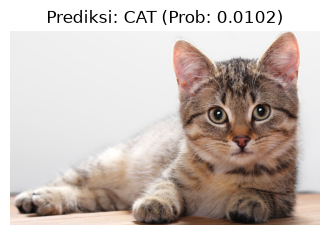

In [15]:
# 2. Prediksi citra kedua (cat_or_dog_2.jpg)
img_path_2 = os.path.join(dataset_path, 'single_prediction', 'cat_or_dog_2.jpg')

if os.path.exists(img_path_2):
    test_image_2 = image.load_img(img_path_2, target_size=(64, 64))
    test_image_2 = image.img_to_array(test_image_2)
    test_image_2 = np.expand_dims(test_image_2, axis=0)
    test_image_2 = test_image_2 / 255.0

    result_2 = cnn.predict(test_image_2)
    print(f"Nilai Prediksi Probabilitas : {result_2[0][0]:.4f}")

    if result_2[0][0] >= 0.5:
        prediction_2 = 'dog'
    else:
        prediction_2 = 'cat'

    print(f"Hasil Prediksi untuk cat_or_dog_2.jpg: {prediction_2.upper()}")

    plt.figure(figsize=(4, 4))
    plt.imshow(image.load_img(img_path_2))
    plt.title(f"Prediksi: {prediction_2.upper()} (Prob: {result_2[0][0]:.4f})")
    plt.axis('off')
    plt.show()

### Kesimpulan Praktikum 1:
1. **Lapisan Konvolusi dan Pooling:** Lapisan `Conv2D` mengekstrak fitur spasial visual seperti tekstur dan tepi, sedangkan `MaxPool2D` mengurangi dimensi spasial dan jumlah parameter sehingga mempercepat komputasi dan mengurangi risiko *overfitting*.
2. **Augmentasi Data:** Penggunaan `ImageDataGenerator` dengan transformasi *shear*, *zoom*, dan *horizontal flip* membantu memperkaya variasi data latih, membuat model lebih tahan banting (*robust*) terhadap variasi sudut dan posisi objek.
3. **Klasifikasi Citra Biner:** Arsitektur CNN dengan 2 layer konvolusi, flattening, dan dense layer dengan fungsi aktivasi output Sigmoid berhasil mengklasifikasikan citra kucing dan anjing dengan akurasi yang baik pada data uji.